In [1]:
import neuron
from neuron import h
import matplotlib.pyplot as plt
from neuron.units import ms, mV
import numpy as np
pth_mod = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod'
pth_mod_inh = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/models/fs_internrn_neuron/mod'
pth_data = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/data/l23'
figpth = '/Users/katharinaduecker/Documents/projects_brown/hnn_dev/figures/newl3_iascone/'
# import os
# os.mkdir(figpth)
from cell_builder_utils import l2_params, _get_dends, _get_pyr_soma, Cell
from iascone_mechs_utils import Mechs, get_iascone_params, Ih_condu_apical, distribute_gbar
from plot_utils import fig_conductances, fig_compartments
from functools import partial
from scipy.signal import find_peaks
from hnn_core.viz import plot_cell_morphology

import os
import pandas as pd
from scipy import signal
from plot_utils import fig_conductances, fig_compartments
from matplotlib.gridspec import GridSpec

h.load_file('stdrun.hoc')


1.0

In [2]:
iascone_model_params = {'soma': {'NaTs2_t_l23': 20_400e-4*0.5,
                                'SKv3_1': 6_930e-4*0.2,
                                'Nap_Et2': 1e-4,
                                'Ca_HVA': 9.92e-04,
                                'Ca_LVAst': 34.3e-4*1.5,
                                'SK_E2': 0.099433*0.001,
                                'pas': 1.0 / 12000.0,
                                'Ih': 0.000080*5,
                                'Im': 8e-3},
                        'dend': {'NaTa_t_l23': 0.008009,
                                'SKv3_1': 0.000513*15,
                                'Ca_HVA': 0.000374e-2*100,
                                'Ca_LVAst': 0.000778e-2*100,
                                'pas': 1.0 / 12000.0,
                                'Ih': {'gbar': 0.000080*10, 'offset': -0.869600, 'slope':4, 'factor_exp':1/110},
                                'Im': 8e-3},
                        'e_pas': -85}



section_params, end_pts, cell_tree = l2_params()

# build sections
section_names = list(end_pts.keys())

sections = _get_dends(section_params, 'L2Pyr', section_names, end_pts)
sections['soma'] = _get_pyr_soma(section_params, 'L2Pyr', end_pts['soma'])

mech_class = Mechs(pth_mod)


In [3]:
l2_allen = pd.read_csv(os.path.join(pth_data, 'ephys_l2.csv'))
l3_allen = pd.read_csv(os.path.join(pth_data, 'ephys_l3.csv'))

# convert AP width to ms

l2_allen.ap_width *= 1000
l3_allen.ap_width *= 1000

ephys_measures = dict()

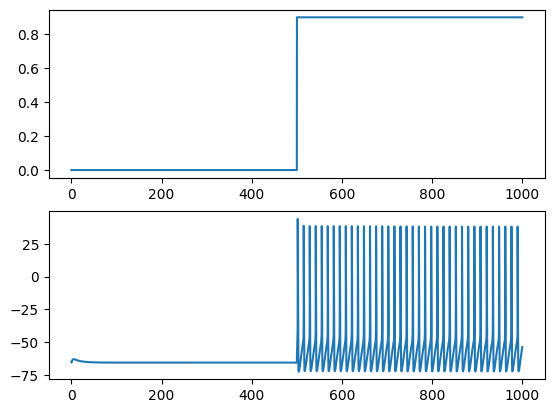

In [4]:
# add stimulation

l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramdial', gid=0)

l2pyr.build()
l2pyr = mech_class.add_mechs(l2pyr, iascone_model_params)

stim = h.IClamp(l2pyr._nrn_sections['soma'](0.5))

stim.delay = 500
stim.dur = 500
stim.amp = 0.9
clamp_current = h.Vector().record(stim._ref_i)

t = h.Vector().record(h._ref_t)
soma_v = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)

h.celsius = 37
h.dt = 0.01
h.finitialize(-65 * mV)
h.continuerun(1000 * ms)

fig, ax = plt.subplots(2,1)

ax[0].plot(t,clamp_current)
ax[1].plot(t,soma_v)

# RMP
ephys_measures['RMP'] = soma_v[np.argmin(np.abs(t-500))]
ax[1].plot(t[np.argmin(np.abs(t-500))],soma_v[np.argmin(np.abs(t-500))])

# inhibitory neurons are extremely excitable!


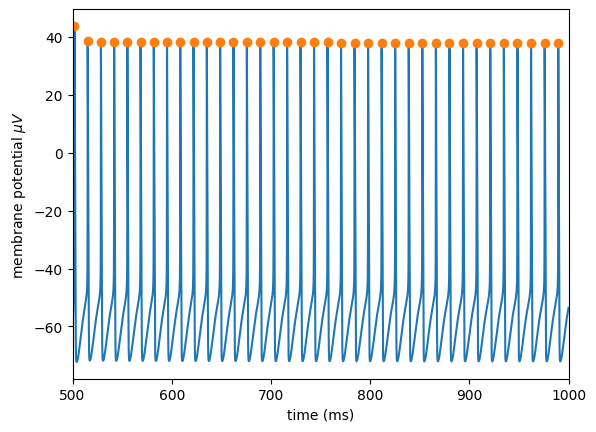

In [5]:
# ISI
from scipy.signal import find_peaks
aps = find_peaks(soma_v,height=0)[0]

plt.plot(t,soma_v)
plt.plot(t.as_numpy()[aps], soma_v.as_numpy()[aps], 'o')
plt.ylabel('membrane potential $\mu V$')
plt.xlabel('time (ms)')
plt.xlim([500, 1000])
ephys_measures['first_isi'] = np.diff(t.as_numpy()[aps])[0]
ephys_measures['mean_isi'] = np.mean(np.diff(t.as_numpy()[aps]))



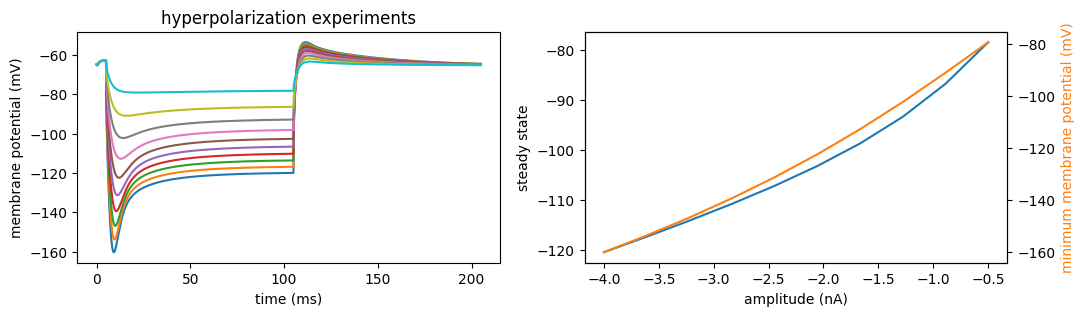

In [6]:
# sag_ratio
from scipy.signal import find_peaks

ampl = np.linspace(-4, -.5, 10)

fig, ax = plt.subplots(1,2, figsize = (12, 3))

soma_v = np.zeros((len(ampl),int(1/h.dt*205+1)))
peak_heights = np.zeros_like(ampl)
steady_state = np.zeros_like(ampl)
min_membr_pot = np.zeros_like(ampl)
sag_ratio = np.zeros_like(ampl)
for i,amp in enumerate(ampl):

    l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramdial', gid=0)

    l2pyr.build()
    l2pyr = mech_class.add_mechs(l2pyr, iascone_model_params)

    stim = h.IClamp(l2pyr._nrn_sections['soma'](0.5))
    stim.delay = 5
    stim.dur = 100
    stim.amp = amp
    clamp_current = h.Vector().record(stim._ref_i)

    t = h.Vector().record(h._ref_t)
    soma_voltg = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)

    h.celsius = 37
    h.dt = 0.01
    h.finitialize(-65 * mV)
    h.continuerun(205 * ms)

    steady_idx = np.argmin(np.abs(t-80))
    soma_v[i] = soma_voltg.as_numpy()
    
    min_membr_pot[i] = np.min(soma_v[i])

    steady_state[i] = soma_v[i][steady_idx]

    ax[0].plot(t, soma_voltg)

ax[0].set_ylabel('membrane potential (mV)')
ax[0].set_xlabel('time (ms)')
ax[0].set_title('hyperpolarization experiments')
ax[1].plot(ampl, steady_state)
ax[1].set_xlabel('amplitude (nA)')
ax[1].set_ylabel('steady state')
ax2 = ax[1].twinx()
ax2.plot(ampl, min_membr_pot, color='tab:orange')
ax2.set_ylabel('minimum membrane potential (mV)', color='tab:orange')

# according to Allen documentation
ephys_measures['sag'] = np.mean((min_membr_pot-steady_state)/min_membr_pot)


## AP measures


/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_33437/1027701957.py:41: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  upstroke = np.mean(np.diff(v_soma.as_numpy()[ap_thresh_idx:int(ap)]))
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_33437/1027701957.py:46: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  downstroke = np.mean(np.diff(v_soma.as_numpy()[int(ap):ap_trough]))
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_33437/1027701957.py:53: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array befor

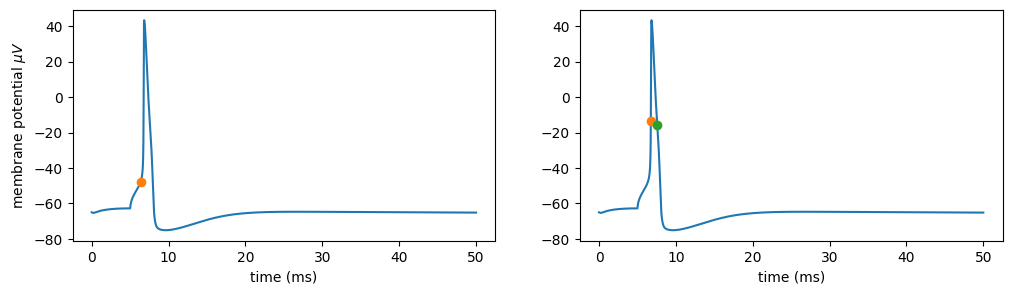

In [7]:
# threshold

l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramdial', gid=0)

l2pyr.build()
l2pyr = mech_class.add_mechs(l2pyr, iascone_model_params)

stim = h.IClamp(l2pyr._nrn_sections['soma'](0.5))
stim.delay = 5
stim.dur = 3
stim.amp = .8
clamp_current = h.Vector().record(stim._ref_i)

t = h.Vector().record(h._ref_t)
v_soma = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)

h.celsius = 37
h.dt = .01
h.finitialize(-65 * mV)
h.continuerun(50 * ms)


ap, properties = find_peaks(v_soma, height=0, width=0)

fig, ax = plt.subplots(1,2, figsize=(12,3))
ax[0].plot(t,v_soma)


smooth_v = signal.savgol_filter(np.diff(v_soma.as_numpy), 101, 3)

ap_thresh_idx = np.where(smooth_v/np.diff(t.as_numpy()) > 20)[0][0]+1

ap_thresh = v_soma[ap_thresh_idx]

ephys_measures['ap_threshold'] = ap_thresh
ax[0].plot(t[ap_thresh_idx], v_soma[ap_thresh_idx],'o')


# upstroke: mean of dV/dt between AP threshold and AP peak
 
upstroke = np.mean(np.diff(v_soma.as_numpy()[ap_thresh_idx:int(ap)]))

# downstroke: minimum value of dV/dt between AP peak and trough

ap_trough = np.argmin(v_soma)
downstroke = np.mean(np.diff(v_soma.as_numpy()[int(ap):ap_trough]))

ephys_measures['upstroke_downstroke'] = np.abs(upstroke/downstroke)

# AP width: width at half maximum

half_max = np.min(v_soma.as_numpy()) + (np.max(v_soma.as_numpy())-np.min(v_soma.as_numpy()))/2
idx1 = np.argmin(np.abs(v_soma.as_numpy()[ap_thresh_idx:int(ap)]-half_max))
idx2 = np.argmin(np.abs(v_soma.as_numpy()[int(ap):ap_trough]-half_max))
ax[1].plot(t,v_soma)
ax[1].plot(t.as_numpy()[idx1+ap_thresh_idx],v_soma.as_numpy()[idx1+ap_thresh_idx],'o')
ax[1].plot(t.as_numpy()[idx2+int(ap)],v_soma.as_numpy()[idx2+int(ap)],'o')
ax[0].set_ylabel('membrane potential $\mu V$')
ax[1].set_xlabel('time (ms)')
ax[0].set_xlabel('time (ms)')

ephys_measures['ap_width'] = t.as_numpy()[idx2+int(ap)]-t.as_numpy()[idx1+ap_thresh_idx]
fig.savefig(figpth+'ap_measures.png')


In [8]:
l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramdial', gid=0)
l2pyr.build()
l2pyr = mech_class.add_mechs(l2pyr, iascone_model_params)

imp = h.Impedance()
imp.loc(0.5, sec=l2pyr._nrn_sections['soma'])
imp.compute(0)
input_resistance_neuron = imp.input(0.5)
print(f'input resistance: {input_resistance_neuron}')

input resistance: 71.11411264976138


Text(0.5, 0, 'amplitude (nA)')

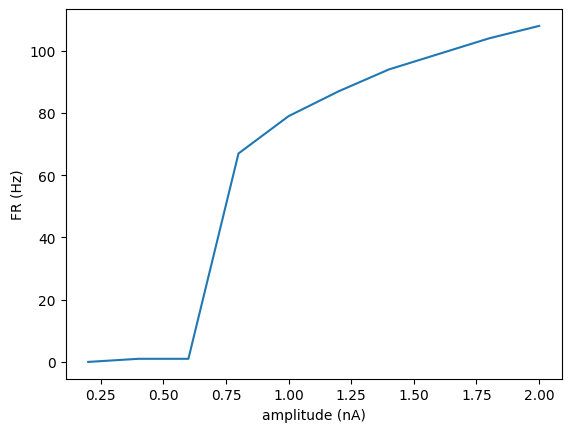

In [9]:
# FR slope
l_stim = 1000

ampl = np.linspace(.2, 2.0, 10)

soma_v = np.zeros((len(ampl),int(1/h.dt*l_stim+1)))
fr = np.zeros_like(ampl)

for i,amp in enumerate(ampl):

    l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramdial', gid=0)
    l2pyr.build()
    l2pyr = mech_class.add_mechs(l2pyr, iascone_model_params)
    stim = h.IClamp(l2pyr._nrn_sections['soma'](0.5))
    stim.delay = 5
    stim.dur = 1000
    stim.amp = amp
    clamp_current = h.Vector().record(stim._ref_i)

    t = h.Vector().record(h._ref_t)
    v_soma = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)

    h.celsius = 37
    h.dt = 0.01
    h.finitialize(-65 * mV)
    h.continuerun((l_stim+stim.delay)* ms)

    pk = find_peaks(v_soma, height=0)

    fr[i] = len(pk[0])



plt.plot(ampl,fr)
plt.ylabel('FR (Hz)')
plt.xlabel('amplitude (nA)')




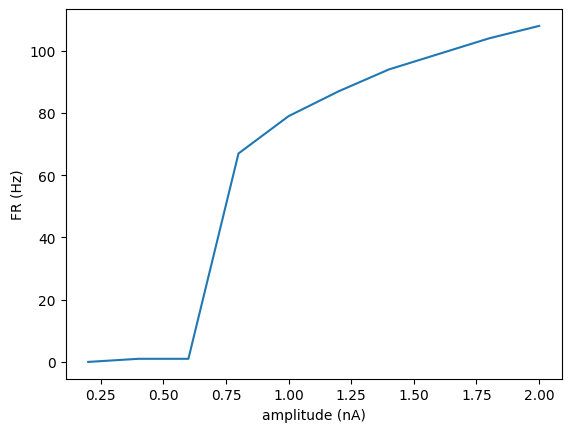

In [10]:
fig, ax = plt.subplots()
ax.plot(ampl,fr)
ax.set_ylabel('FR (Hz)')
ax.set_xlabel('amplitude (nA)')

fig.savefig(figpth+'FR_slope')

In [11]:
pA = 0.001 # nA (convert nA to pA)
ephys_measures['FR_slope'] = np.max(np.gradient(fr))#np.polyfit(ampl,fr,1)[0]
ephys_measures['FR_slope'] *= pA

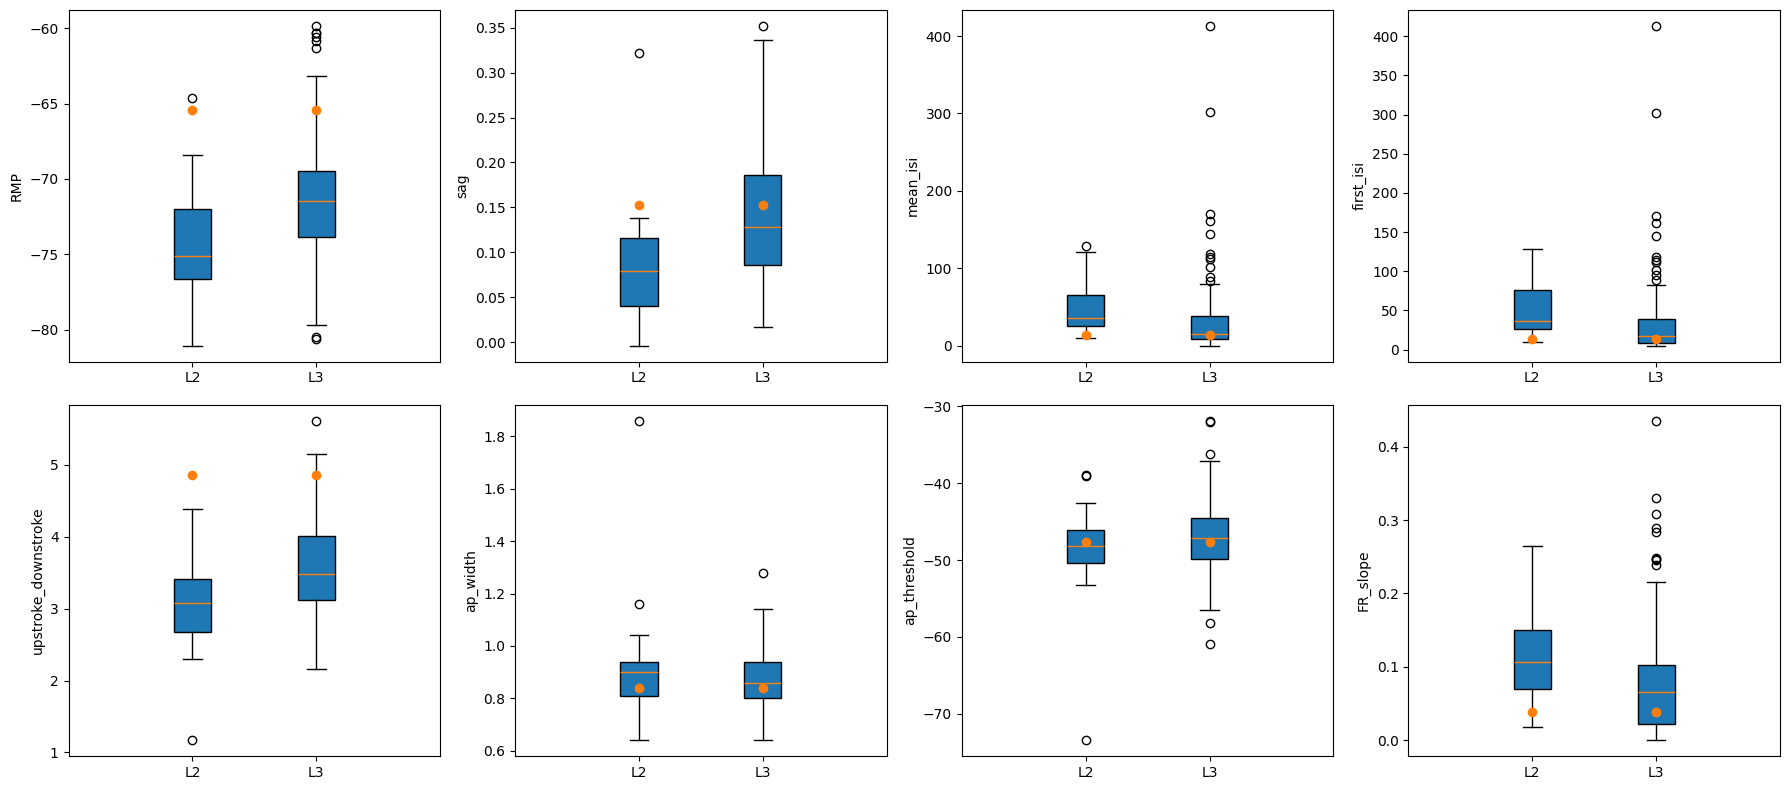

In [12]:
measures = ['RMP', 'sag', 'mean_isi', 'first_isi', 'upstroke_downstroke', 'ap_width', 'ap_threshold', 'FR_slope']

fig, ax = plt.subplots(2,4,figsize=(18,8))
ax = ax.ravel()
for i,m in enumerate(measures):
    ax[i].boxplot([l2_allen[m].dropna(),l3_allen[m].dropna()], positions=[1.25,1.75], vert=True, patch_artist=True)
    ax[i].set_xticklabels(['L2', 'L3'])

    ax[i].plot(1.25, ephys_measures[m], 'o', color='tab:orange')
    ax[i].plot(1.75, ephys_measures[m], 'o', color='tab:orange')
    ax[i].set_ylabel(m)

fig.tight_layout()
fig.savefig(figpth+'l23_cell_vs_allen')

In [13]:
figpth

'/Users/katharinaduecker/Documents/projects_brown/hnn_dev/figures/newl3_iascone/'